# Неделя 20. GPT API и чат-бот на Python

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** разобрать формат Chat Completions, протестировать историю и ошибки offline; подготовить реальный SDK-клиент.

**Два режима:** notebook использует явно авторский FakeClient. `live_api_chatbot.py` — настоящий OpenAI SDK, запускается только вручную с `--live`. Платных запросов при Run All нет.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_20_gpt_api_chatbot"
DATA = WEEK / "datasets"
SEED = 120
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Контракт HTTP и событий

HTTP-коды объясняют класс сбоя. 401 требует исправления credentials; 400 — запроса. Временные 429/5xx могут требовать повторения, но 429 из-за исчерпанной квоты нельзя лечить бесконечными повторами.


,status_code,category,retry,count
0,200,success,False,68
1,400,invalid_request,False,4
2,401,authentication,False,2
3,429,rate_limit,True,9
4,503,service_error,True,7


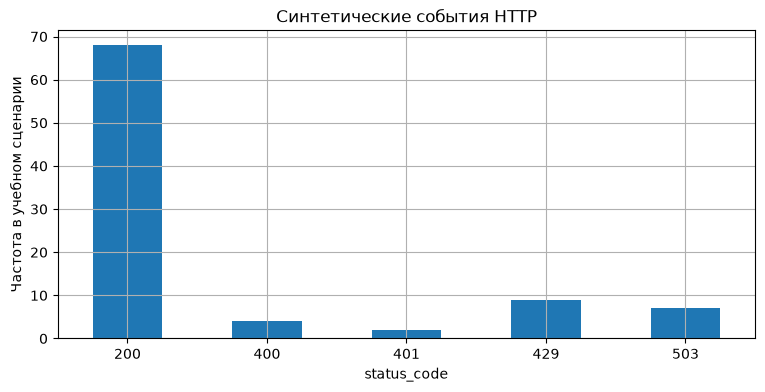

In [2]:
events = pd.read_csv(DATA / 'synthetic_http_events.csv')
display(events)
events.plot.bar(x='status_code', y='count', legend=False, rot=0, title='Синтетические события HTTP')
plt.ylabel('Частота в учебном сценарии'); plt.show()
assert events['count'].sum() == 90


## 2. Запрос Chat Completions

Силлабус рассматривает `messages` и Chat Completions; OpenAI рекомендует Responses для новых интеграций. Здесь изучаем оба интерфейса, не смешивая их схемы. Model ID задается через окружение и должен быть доступен аккаунту.


In [3]:
instructions = 'Объясняй темы ML начинающему на русском. Давай краткий пример и ограничение.'
messages = [{'role': 'system', 'content': instructions},
            {'role': 'user', 'content': 'Зачем нужен test split?'}]
request_preview = {'model': '<OPENAI_MODEL>', 'messages': messages, 'store': False}
print(json.dumps(request_preview, ensure_ascii=False, indent=2))
assert messages[0]['role'] == 'system' and messages[-1]['role'] == 'user'


{
  "model": "<OPENAI_MODEL>",
  "messages": [
    {
      "role": "system",
      "content": "Объясняй темы ML начинающему на русском. Давай краткий пример и ограничение."
    },
    {
      "role": "user",
      "content": "Зачем нужен test split?"
    }
  ],
  "store": false
}


## 3. Разбор ответа: структура ≠ успех

Массив choices может быть пустым, content может отсутствовать, ответ может завершиться по лимиту. Такой результат не следует без проверки сохранять как полноценный ответ. Usage ниже — число в fixture, не оплаченный расход.


In [4]:
fixture = json.loads((DATA / 'chat_completion_fixture.json').read_text(encoding='utf-8'))
def parse_completion(payload):
    choices = payload.get('choices', [])
    if not choices:
        raise ValueError('empty_choices')
    choice = choices[0]
    text = choice.get('message', {}).get('content')
    if choice.get('finish_reason') != 'stop' or not isinstance(text, str) or not text.strip():
        raise ValueError('incomplete_or_empty_text')
    return text
print(parse_completion(fixture))
assert fixture['usage']['total_tokens'] == 44


Train обучает модель; test оценивает обобщение.


## 4. FakeClient для проверки управляющего кода

Имитируем 429 → 503 → success без сети и sleep. Повторять нужно строго ограниченное число раз. Эта проверка не подтверждает аутентификацию и совместимость live-модели.


In [5]:
class SimulatedAPIError(Exception):
    def __init__(self, status, quota_exhausted=False):
        self.status, self.quota_exhausted = status, quota_exhausted
        super().__init__(f'simulated_status_{status}')

class FakeClient:
    def __init__(self, outcomes):
        self.outcomes = iter(outcomes)
        self.calls = 0
    def complete(self, messages):
        self.calls += 1
        outcome = next(self.outcomes)
        if isinstance(outcome, Exception):
            raise outcome
        return outcome

def call_with_retry(client, messages, max_attempts=3):
    delays = []  # Здесь только план ожиданий, без реального sleep.
    for attempt in range(max_attempts):
        try:
            return parse_completion(client.complete(messages)), delays
        except SimulatedAPIError as error:
            retryable = (error.status == 429 or error.status >= 500) and not error.quota_exhausted
            if not retryable or attempt + 1 == max_attempts:
                raise
            delays.append(min(2 ** attempt, 8))
    raise RuntimeError('unreachable')

fake = FakeClient([SimulatedAPIError(429), SimulatedAPIError(503), fixture])
answer, delays = call_with_retry(fake, messages)
assert fake.calls == 3 and delays == [1, 2]
print(answer, '\nПлан задержек:', delays)


Train обучает модель; test оценивает обобщение. 
План задержек: [1, 2]


## 5. Ошибки, которые не надо повторять

Негативные тесты подтверждают, что запрос не зацикливается. В настоящем SDK соответствующие классы — AuthenticationError, BadRequestError, RateLimitError, APIConnectionError и APIStatusError; готовый скрипт использует их.


In [6]:
for error in [SimulatedAPIError(401), SimulatedAPIError(400), SimulatedAPIError(429, True)]:
    fake = FakeClient([error])
    try:
        call_with_retry(fake, messages)
    except SimulatedAPIError:
        pass
    else:
        raise AssertionError('Failure must surface')
    assert fake.calls == 1
print('401, 400 и exhausted quota не повторяются в нашей offline-политике.')


401, 400 и exhausted quota не повторяются в нашей offline-политике.


## 6. История обновляется только после успеха

Сначала создаем candidate history. Добавляем user/assistant в постоянную историю только после проверенного ответа. Иначе повторяющиеся ошибки могут оставлять «висящие» пользовательские сообщения и менять следующий запрос.


In [7]:
class ChatSession:
    def __init__(self, instructions):
        self.history = [{'role': 'system', 'content': instructions}]
    def ask(self, text, client):
        if not isinstance(text, str) or not text.strip():
            raise ValueError('empty_input')
        candidate = self.history + [{'role': 'user', 'content': text.strip()}]
        answer, _ = call_with_retry(client, candidate)
        self.history = candidate + [{'role': 'assistant', 'content': answer}]
        return answer

session = ChatSession(instructions)
session.ask('Зачем нужен test?', FakeClient([fixture]))
before = list(session.history)
try:
    session.ask('Еще вопрос', FakeClient([SimulatedAPIError(401)]))
except SimulatedAPIError:
    pass
assert session.history == before and len(session.history) == 3
display(pd.DataFrame(session.history))


,role,content
0,system,Объясняй темы ML начинающему на русском. Давай...
1,user,Зачем нужен test?
2,assistant,Train обучает модель; test оценивает обобщение.


## 7. Ограничение контекста по полным turns

Сохраняем system и последние полные пары user/assistant. Удалять ровно N сообщений опасно: первым может остаться ответ без вопроса. Окно из K turns — учебная политика; для реальной модели дополнительно учитывайте token budget.


In [8]:
def keep_last_turns(history, turns):
    if turns < 0:
        raise ValueError('turns must be >= 0')
    tail = history[1:]
    assert len(tail) % 2 == 0
    assert all(tail[i]['role'] == 'user' and tail[i+1]['role'] == 'assistant'
               for i in range(0, len(tail), 2))
    return [history[0]] + (tail[-2*turns:] if turns else [])
for _ in range(4):
    session.ask('Приведи пример', FakeClient([fixture]))
bounded = keep_last_turns(session.history, 2)
assert len(bounded) == 5 and bounded[1]['role'] == 'user'
assert len(keep_last_turns(session.history, 0)) == 1
print('Сообщений до/после:', len(session.history), len(bounded))


Сообщений до/после: 11 5


## 8. Переменные окружения без раскрытия секрета

Notebook не читает ключ и не печатает окружение. Реальный скрипт проверяет наличие OPENAI_API_KEY и OPENAI_MODEL. `.env.example` содержит только имена; настоящий ключ вводится локально и не коммитится.


In [9]:
required_names = ['OPENAI_API_KEY', 'OPENAI_MODEL']
print('Для live-скрипта нужны:', ', '.join(required_names))
print('Запуск по умолчанию ничего не отправляет; нужен флаг --live.')
script = (WEEK / 'practice' / 'live_api_chatbot.py').read_text(encoding='utf-8')
assert 'client.chat.completions.create' in script and 'client.responses.create' in script
assert '--live' in script


Для live-скрипта нужны: OPENAI_API_KEY, OPENAI_MODEL
Запуск по умолчанию ничего не отправляет; нужен флаг --live.


## 9. Не смешиваем схемы Responses и Chat

У Chat ответ читается из choices[0].message.content, у SDK Responses удобный текст находится в output_text. В примере Responses передаем полную клиентскую историю и инструкции, не полагаясь на серверную память.


In [10]:
comparison = pd.DataFrame([
    {'API': 'Chat Completions', 'input': 'messages', 'output': 'choices[0].message.content', 'history': 'client-managed'},
    {'API': 'Responses', 'input': 'instructions + input', 'output': 'output_text', 'history': 'client-managed in our script'},
])
display(comparison)


,API,input,output,history
0,Chat Completions,messages,choices[0].message.content,client-managed
1,Responses,instructions + input,output_text,client-managed in our script


## 10. Что подтверждено запуском

Локально проверены parser, retry-policy и атомарность истории. Настоящие auth, quota, latency, доступность model ID и API outputs еще не проверены; они проверяются по соседней инструкции LIVE_API_LAB.md.


In [11]:
validation_status = {'offline_contracts': 'passed', 'live_api': 'not_run'}
display(validation_status)


{'offline_contracts': 'passed', 'live_api': 'not_run'}

## Источники и следующий шаг

- [OpenAI Python SDK](https://developers.openai.com/api/reference/python)
- [OpenAI error codes](https://developers.openai.com/api/docs/guides/error-codes)
- [Responses migration guide](https://developers.openai.com/api/docs/guides/migrate-to-responses)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
